In [1]:
# Permite ejecutar el notebook desde VS Code o JupyterLab, en raíz o notebooks/
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Abre la carpeta hotel_yield_ml como proyecto en VS Code.'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 40)
from pipeline import load_data,prepare
raw = load_data()
display(raw.head())
print('Dimensiones:',raw.shape)
display(raw.dtypes.value_counts())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Dimensiones: (119390, 32)


int64      16
object     12
float64     4
Name: count, dtype: int64

## 1 · Calidad de datos

In [2]:
missing = pd.DataFrame({'n_missing':raw.isna().sum(), 'pct_missing':raw.isna().mean()*100})
display(missing.query('n_missing > 0').sort_values('n_missing',ascending=False))
print('Filas exactamente repetidas (no borrar automáticamente):',raw.duplicated().sum())

,n_missing,pct_missing
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


Filas exactamente repetidas (no borrar automáticamente): 31994


## 2 · Variables objetivo
Clasificación: `is_canceled` = 0/1. Regresión: `adr` = tarifa diaria promedio observada. Verifica valores negativos o extremos.

In [3]:
display(raw.groupby('hotel').agg(n=('is_canceled','size'),cancel_rate=('is_canceled','mean'),adr_mediana=('adr','median')).round(3))
display(raw.adr.describe(percentiles=[.01,.25,.5,.75,.95,.99]))

,n,cancel_rate,adr_mediana
hotel,,,
City Hotel,79330,0.417,99.9
Resort Hotel,40060,0.278,75.0


count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
1%            0.000000
25%          69.290000
50%          94.575000
75%         126.000000
95%         193.500000
99%         252.000000
max        5400.000000
Name: adr, dtype: float64

## 3 · Ingeniería simple de variables
`total_nights` = noches de semana + fin de semana. `total_guests` = adultos, niños y bebés. El mes se transforma de nombre a número.

In [5]:
df=prepare(raw)
display(df[['hotel','arrival_date','lead_time','total_nights','total_guests','is_canceled','adr']].head())

,hotel,arrival_date,lead_time,total_nights,total_guests,is_canceled,adr
0,Resort Hotel,2015-07-01,342,0,2.0,0,0.0
1,Resort Hotel,2015-07-01,737,0,2.0,0,0.0
2,Resort Hotel,2015-07-01,7,1,1.0,0,75.0
3,Resort Hotel,2015-07-01,13,1,1.0,0,75.0
4,Resort Hotel,2015-07-01,14,2,2.0,0,98.0


## 4 · Visualización por hotel y por temporada
Las tendencias representan **asociaciones históricas**; no atribuir causalidad a un mes, un hotel o un precio.

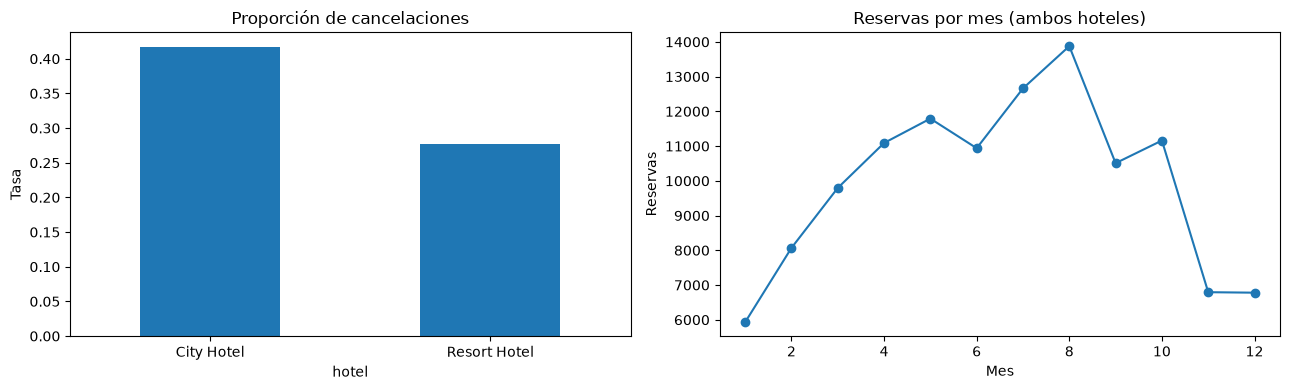

In [6]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
df.groupby('hotel').is_canceled.mean().plot(kind='bar',ax=axes[0],title='Proporción de cancelaciones');axes[0].set_ylabel('Tasa');axes[0].tick_params(axis='x',rotation=0)
df.groupby('arrival_month_num').size().plot(marker='o',ax=axes[1],title='Reservas por mes (ambos hoteles)');axes[1].set(xlabel='Mes',ylabel='Reservas');plt.tight_layout();plt.show()